## Interval Analysis

In [2]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


100%|██████████| 9.91M/9.91M [00:00<00:00, 36.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.15MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.20MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.37MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [3]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [4]:
train_model(model, 10)
test_model(model)

Epoch 1/10, Loss: 2.012
Epoch 2/10, Loss: 1.729
Epoch 3/10, Loss: 1.627
Epoch 4/10, Loss: 1.596
Epoch 5/10, Loss: 1.582
Epoch 6/10, Loss: 1.572
Epoch 7/10, Loss: 1.566
Epoch 8/10, Loss: 1.561
Epoch 9/10, Loss: 1.557
Epoch 10/10, Loss: 1.553
Accuracy on images: 92.76


### Write the interval analysis for the simple model

In [1]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

sanity (radius=0, should equal clean acc): 92.76%
eps = 0.01  verified accuracy = 68.81%
eps = 0.02  verified accuracy = 22.54%
eps = 0.03  verified accuracy = 3.95%
eps = 0.04  verified accuracy = 0.40%
eps = 0.05  verified accuracy = 0.01%
eps = 0.06  verified accuracy = 0.00%
eps = 0.07  verified accuracy = 0.00%
eps = 0.08  verified accuracy = 0.00%
eps = 0.09  verified accuracy = 0.00%
eps = 0.10  verified accuracy = 0.00%


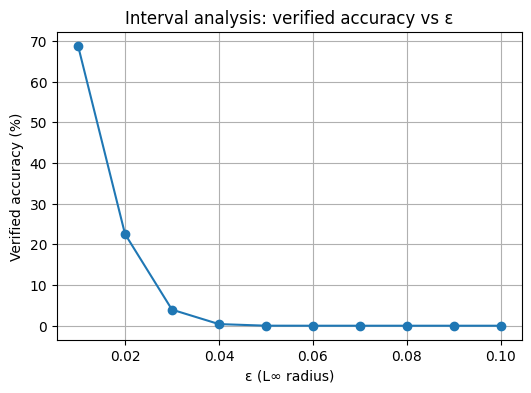

In [6]:
## Interval analysis for the simple model
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

model.eval()
mlp = model[1]
device = next(mlp.parameters()).device
w_in,  bias_in  = mlp.fc.weight.detach(),  mlp.fc.bias.detach()
w_out, bias_out = mlp.fc2.weight.detach(), mlp.fc2.bias.detach()
PIXEL_MEAN, PIXEL_STD = 0.1307, 0.3081   # MNIST train-set stats; must match model[0]

def propagate_linear(low, high, weight, bias):
    w_pos, w_neg = weight.clamp(min=0), weight.clamp(max=0)
    new_low  = low  @ w_pos.T + high @ w_neg.T + bias
    new_high = high @ w_pos.T + low  @ w_neg.T + bias
    return new_low, new_high

@torch.no_grad()
def is_certified(images, labels, radius):
    flat = images.view(images.shape[0], -1)
    low  = ((flat - radius).clamp(0, 1) - PIXEL_MEAN) / PIXEL_STD
    high = ((flat + radius).clamp(0, 1) - PIXEL_MEAN) / PIXEL_STD

    low, high = propagate_linear(low, high, w_in, bias_in)
    low, high = F.relu(low), F.relu(high)

    n_cls = w_out.shape[0]
    eye = torch.eye(n_cls, device=flat.device)
    diff_mat = eye[labels].unsqueeze(1) - eye.unsqueeze(0)   # row j: e_y - e_j
    margin_w = diff_mat @ w_out
    margin_b = diff_mat @ bias_out
    mw_pos, mw_neg = margin_w.clamp(min=0), margin_w.clamp(max=0)
    margin_low = (mw_pos @ low.unsqueeze(2) + mw_neg @ high.unsqueeze(2)).squeeze(2) + margin_b
    margin_low[torch.arange(len(labels)), labels] = float('inf')
    return margin_low.min(dim=1).values >= 0

@torch.no_grad()
def certified_accuracy(data_loader, radius):
    n_verified, n_total = 0, 0
    for images, labels in data_loader:
        images, labels = images.to(device), labels.to(device)
        n_verified += is_certified(images, labels, radius).sum().item()
        n_total += len(labels)
    return 100.0 * n_verified / n_total

print(f"sanity (radius=0, should equal clean acc): {certified_accuracy(test_loader, 0.0):.2f}%")
radii = torch.linspace(0.01, 0.1, 10).tolist()
cert_accs = [certified_accuracy(test_loader, r) for r in radii]
for r, acc in zip(radii, cert_accs):
    print(f"eps = {r:.2f}  verified accuracy = {acc:.2f}%")


plt.figure(figsize=(6, 4))
plt.plot(radii, cert_accs, marker='o')
plt.xlabel('ε (L∞ radius)')
plt.ylabel('Verified accuracy (%)')
plt.title('Interval analysis: verified accuracy vs ε')
plt.grid(True)
plt.show()